shape: (140256, 370)


,MT_001,MT_002,MT_003,MT_004,MT_005,MT_006,MT_007,MT_008,MT_009,MT_010,...,MT_361,MT_362,MT_363,MT_364,MT_365,MT_366,MT_367,MT_368,MT_369,MT_370
2011-01-01 00:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 00:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 00:45:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 01:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 140256 entries, 2011-01-01 00:15:00 to 2015-01-01 00:00:00
Columns: 370 entries, MT_001 to MT_370
dtypes: float64(370)
memory usage: 397.0 MB


None

Top missing columns:


MT_001    0.0
MT_002    0.0
MT_003    0.0
MT_004    0.0
MT_005    0.0
MT_006    0.0
MT_007    0.0
MT_008    0.0
MT_009    0.0
MT_010    0.0
dtype: float64

<Figure size 1200x400 with 0 Axes>

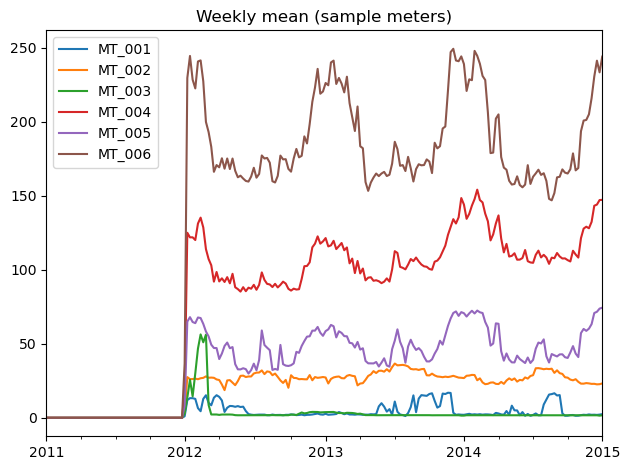

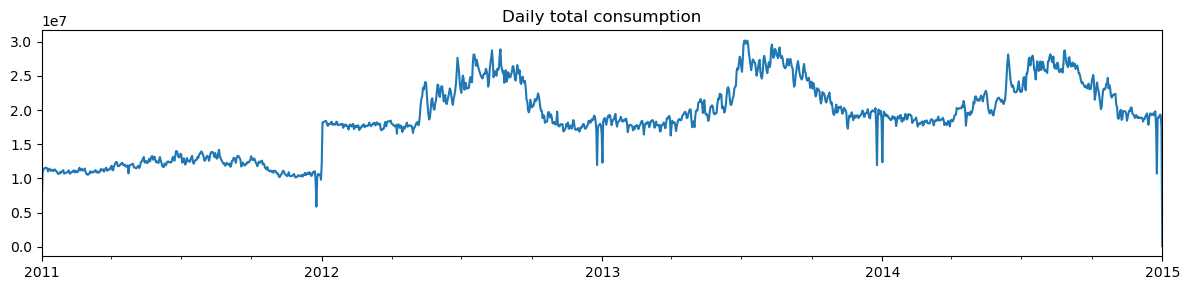

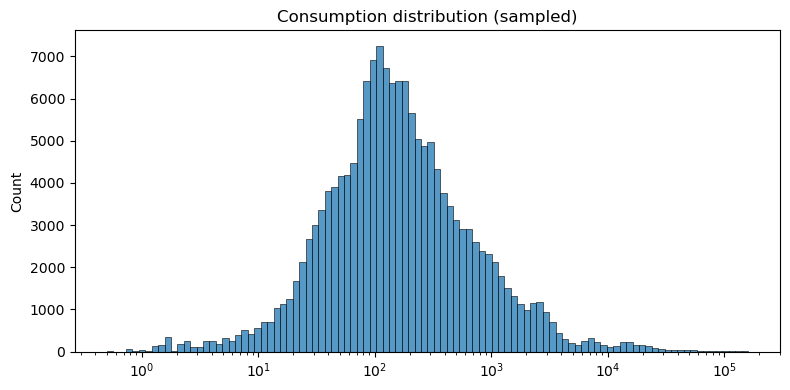

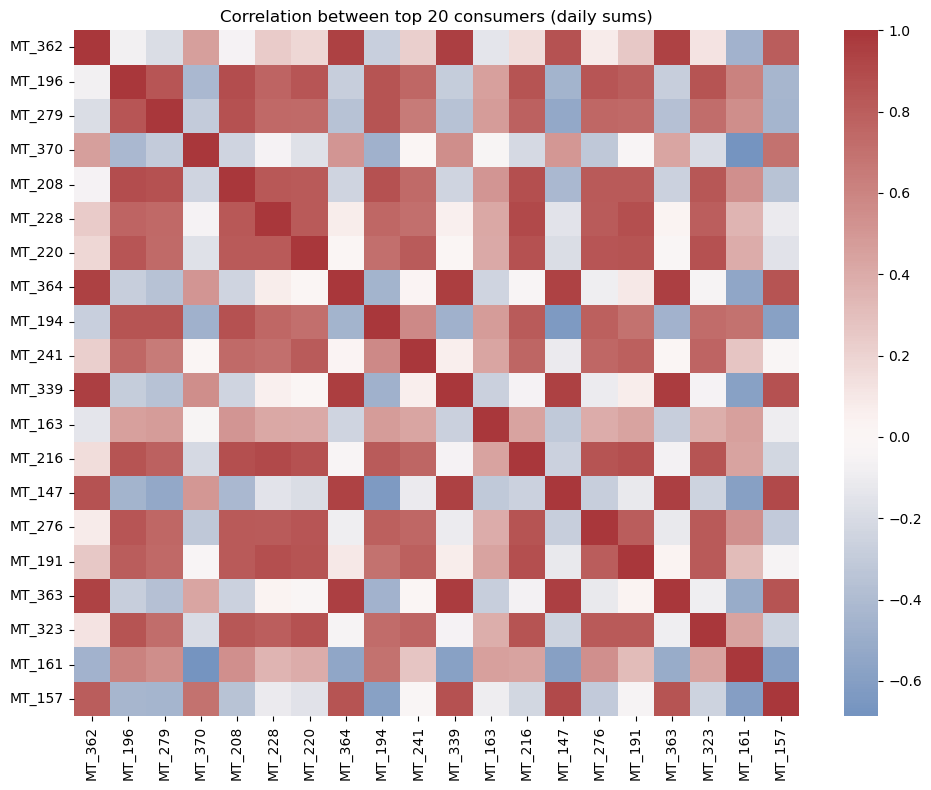

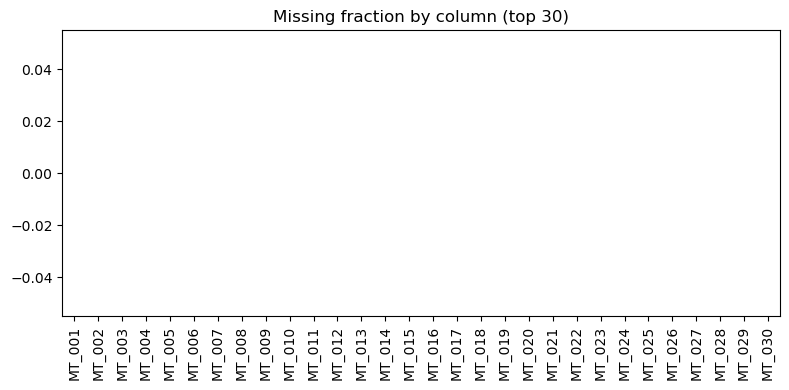

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

import matplotlib.pyplot as plt

path = "datasets/electricity-energy-dataset/LD2011_2014.csv"

# robust load (tries common delimiters)
try:
    df = pd.read_csv(path, index_col=0, parse_dates=True)
except Exception:
    df = pd.read_csv(path, index_col=0, parse_dates=True, sep=';')

# quick overview
print("shape:", df.shape)
display(df.head())
display(df.info())

# missing values per column
missing = df.isna().mean().sort_values(ascending=False)
print("Top missing columns:")
display(missing.head(10))

# pick a small set of columns to plot time series (first 6 non-null columns)
cols_ts = df.columns[df.notna().any()].tolist()[:6]
plt.figure(figsize=(12, 4))
(df[cols_ts].resample('W').mean()).plot(title="Weekly mean (sample meters)", legend=True)
plt.tight_layout()

# total system load (daily)
total_daily = df.sum(axis=1).resample('D').sum()
plt.figure(figsize=(12, 3))
total_daily.plot(title="Daily total consumption")
plt.tight_layout()

# distribution of values (sample to limit memory)
vals = df.stack().sample(min(200000, int(df.stack().size)), random_state=0)
plt.figure(figsize=(8, 4))
sns.histplot(vals, bins=100, log_scale=(True, False))
plt.title("Consumption distribution (sampled)")
plt.tight_layout()

# heatmap of correlations for top N consumers by mean
top_n = 20
top_cols = df.mean().sort_values(ascending=False).head(top_n).index
# resample to daily to reduce noise & memory
corr = df[top_cols].resample('D').sum().corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="vlag", center=0)
plt.title(f"Correlation between top {top_n} consumers (daily sums)")
plt.tight_layout()

# bar plot of top missing ratios (if any)
plt.figure(figsize=(8, 4))
missing.head(30).plot.bar()
plt.title("Missing fraction by column (top 30)")
plt.tight_layout()

plt.show()

shape: (100000, 6)


,M4id,category,Frequency,Horizon,SP,StartingDate
0,Y1,Macro,1,6,Yearly,01-01-79 12:00
1,Y2,Macro,1,6,Yearly,01-01-79 12:00
2,Y3,Macro,1,6,Yearly,01-01-79 12:00
3,Y4,Macro,1,6,Yearly,01-01-79 12:00
4,Y5,Macro,1,6,Yearly,01-01-79 12:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   M4id          100000 non-null  object
 1   category      100000 non-null  object
 2   Frequency     100000 non-null  int64 
 3   Horizon       100000 non-null  int64 
 4   SP            100000 non-null  object
 5   StartingDate  100000 non-null  object
dtypes: int64(2), object(4)
memory usage: 4.6+ MB


None

Top missing columns:


M4id            0.0
category        0.0
Frequency       0.0
Horizon         0.0
SP              0.0
StartingDate    0.0
dtype: float64

,Frequency,Horizon
count,100000.000000,100000.000000
mean,7.095220,12.777170
std,5.027783,5.859561
min,1.000000,6.000000
25%,1.000000,8.000000
50%,4.000000,14.000000
75%,12.000000,18.000000
max,24.000000,48.000000


<Figure size 1200x600 with 0 Axes>

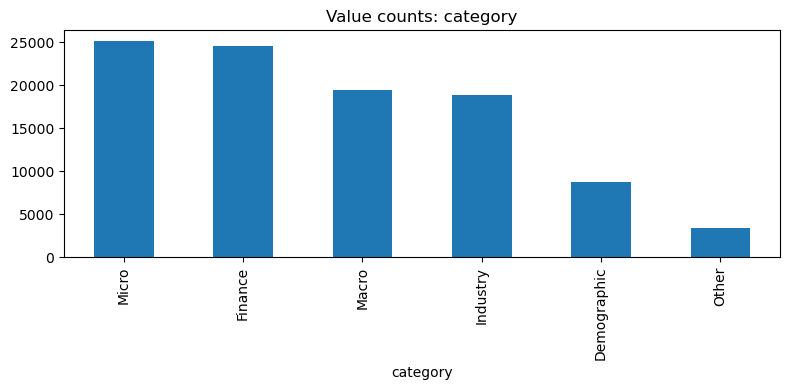

<Figure size 640x480 with 0 Axes>

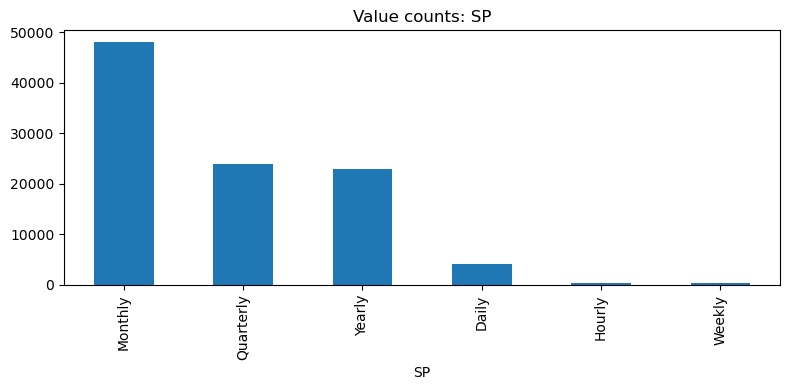

<Figure size 640x480 with 0 Axes>

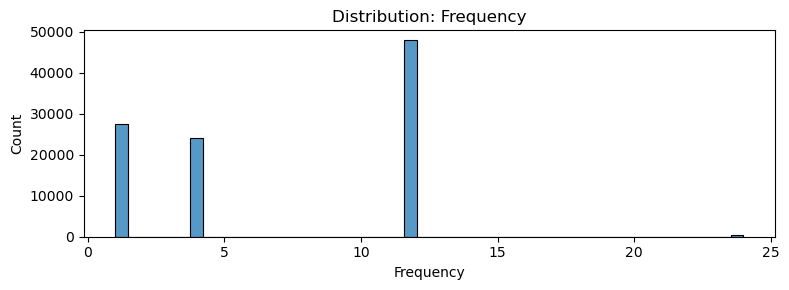

<Figure size 640x480 with 0 Axes>

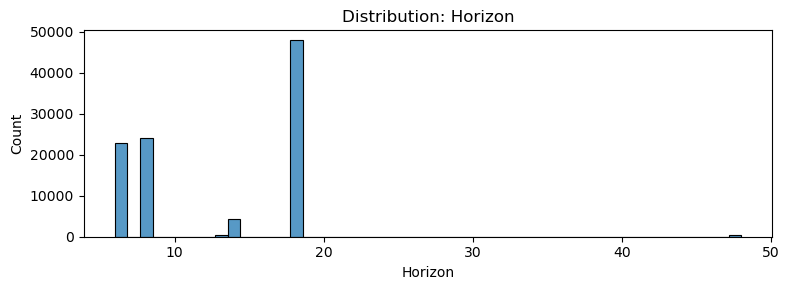

C:\Users\SafinSharma\AppData\Local\Temp\ipykernel_22496\1479787969.py:47: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dt = pd.to_datetime(m4_info[c], errors='coerce')


<Figure size 640x480 with 0 Axes>

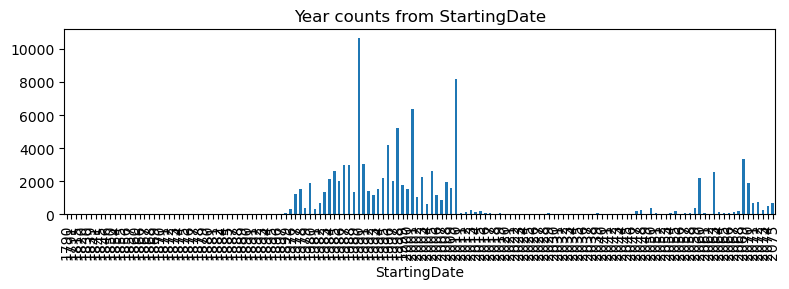

In [2]:
# EDA for M4-info.csv
m4_path = "datasets/m4-finance-dataset/M4-methods-master/Dataset/M4-info.csv"
m4_info = pd.read_csv(m4_path)

print("shape:", m4_info.shape)
display(m4_info.head())
display(m4_info.info())

# missing fractions
missing_m4 = m4_info.isna().mean().sort_values(ascending=False)
print("Top missing columns:")
display(missing_m4.head(10))

# basic numeric summary
num_cols = m4_info.select_dtypes(include=[np.number]).columns.tolist()
if num_cols:
    display(m4_info[num_cols].describe())

# automatic plots:
plt.figure(figsize=(12, 6))
# categorical columns: plot value counts for those with limited uniques
cat_cols = m4_info.select_dtypes(include=['object', 'category']).columns.tolist()
plotted = 0
for c in cat_cols:
    if m4_info[c].nunique(dropna=False) <= 50:
        plt.clf()
        plt.figure(figsize=(8, 4))
        m4_info[c].value_counts(dropna=False).head(30).plot.bar()
        plt.title(f"Value counts: {c}")
        plt.tight_layout()
        plt.show()
        plotted += 1

# numeric distributions
for c in num_cols:
    plt.clf()
    plt.figure(figsize=(8, 3))
    sns.histplot(m4_info[c].dropna(), bins=50, kde=False)
    plt.title(f"Distribution: {c}")
    plt.tight_layout()
    plt.show()

# try to detect and plot date/start columns (year distribution)
date_candidates = [c for c in m4_info.columns if any(k in c.lower() for k in ("date", "start", "year"))]
for c in date_candidates:
    try:
        dt = pd.to_datetime(m4_info[c], errors='coerce')
        if dt.notna().any():
            plt.clf()
            plt.figure(figsize=(8, 3))
            dt.dt.year.dropna().astype(int).value_counts().sort_index().plot.bar()
            plt.title(f"Year counts from {c}")
            plt.tight_layout()
            plt.show()
    except Exception:
        pass

DATASET SHAPE
(15622, 15)


COLUMN NAMES
['Domain Code', 'Domain', 'Area Code (M49)', 'Area', 'Element Code', 'Element', 'Item Code (CPC)', 'Item', 'Year Code', 'Year', 'Unit', 'Value', 'Flag', 'Flag Description', 'Note']


DATA TYPES
Domain Code          object
Domain               object
Area Code (M49)       int64
Area                 object
Element Code          int64
Element              object
Item Code (CPC)     float64
Item                 object
Year Code             int64
Year                  int64
Unit                 object
Value               float64
Flag                 object
Flag Description     object
Note                 object
dtype: object


FIRST 5 ROWS
  Domain Code                        Domain  Area Code (M49)   Area  \
0         QCL  Crops and livestock products              356  India   
1         QCL  Crops and livestock products              356  India   
2         QCL  Crops and livestock products              356  India   
3         QCL  Crops and livesto

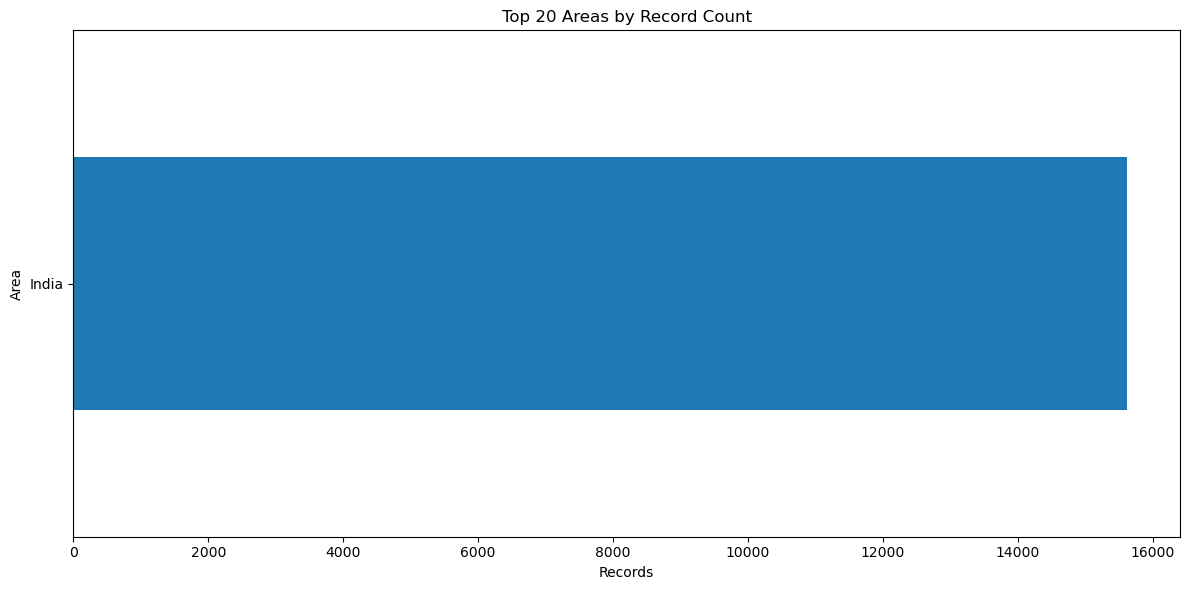

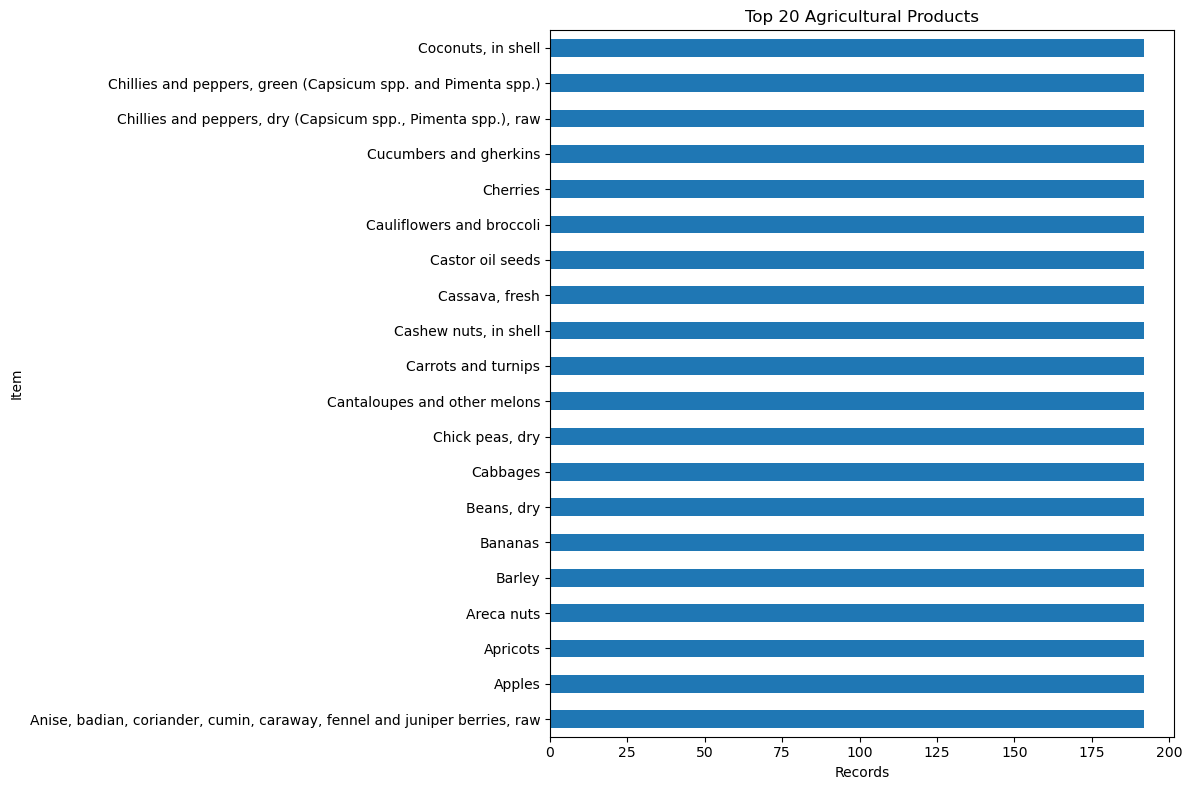

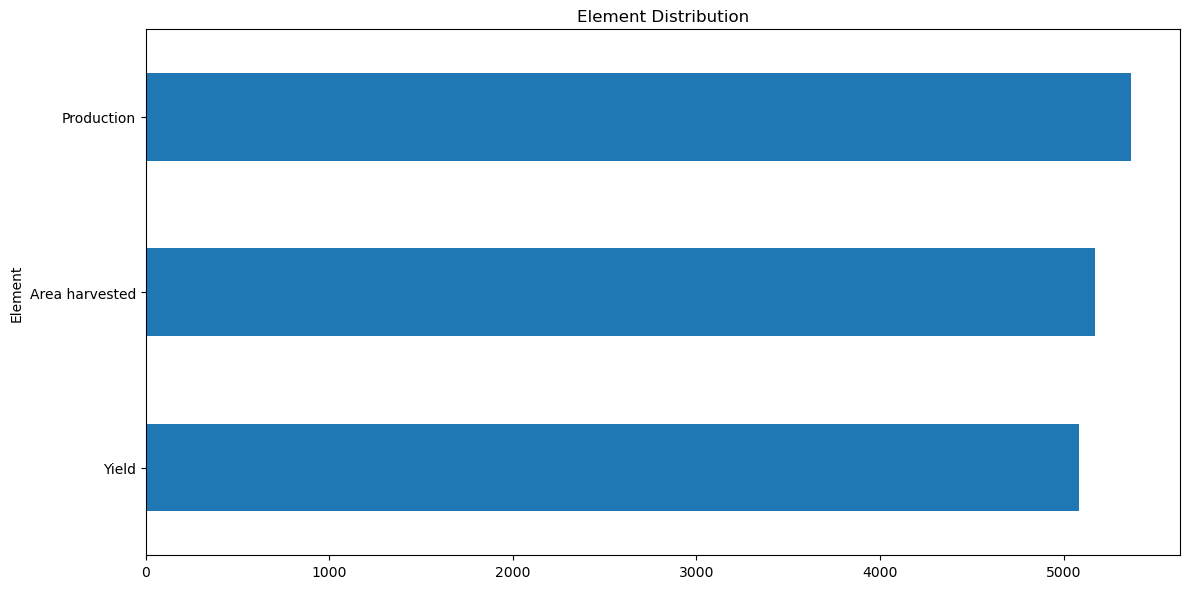

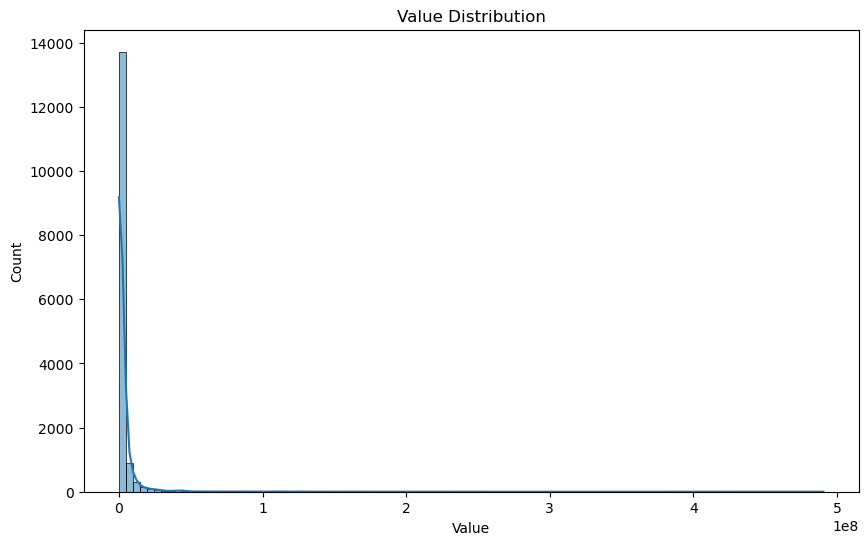

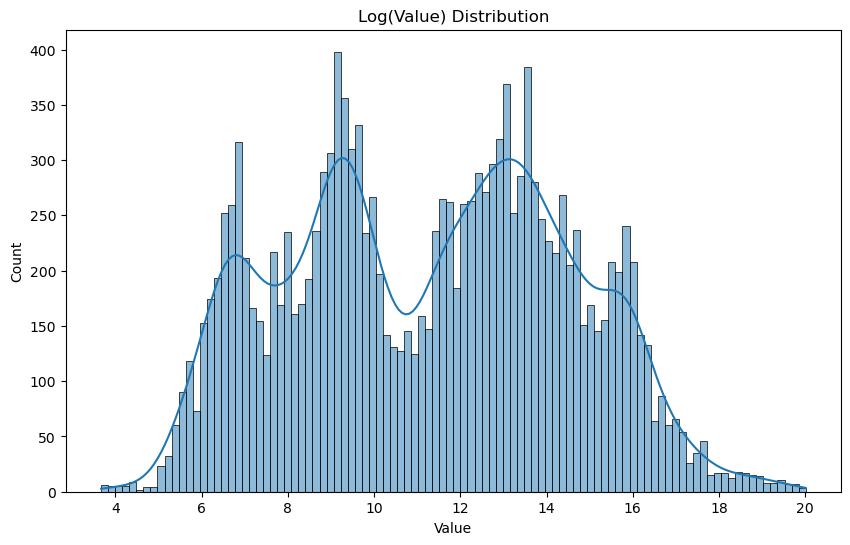



OUTLIERS
Outlier Rows: 2,579


TOP 10 LARGEST VALUES
        Area        Item     Element  Year         Value
13957  India  Sugar cane  Production  2023  4.905334e+08
13960  India  Sugar cane  Production  2024  4.531585e+08
13954  India  Sugar cane  Production  2022  4.394249e+08
13945  India  Sugar cane  Production  2019  4.054162e+08
13951  India  Sugar cane  Production  2021  4.053987e+08
13942  India  Sugar cane  Production  2018  3.799048e+08
13948  India  Sugar cane  Production  2020  3.705003e+08
13933  India  Sugar cane  Production  2015  3.623330e+08
13924  India  Sugar cane  Production  2012  3.610370e+08
13909  India  Sugar cane  Production  2007  3.555197e+08


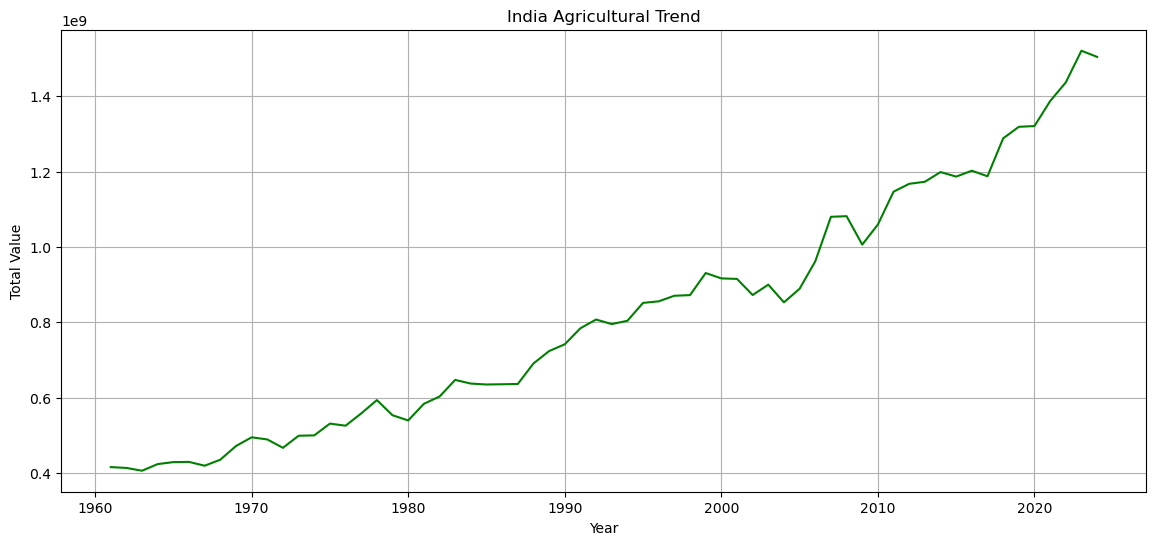


EDA COMPLETE


In [2]:
# =========================
# FAOSTAT DATASET FULL EDA
# =========================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("default")
pd.set_option("display.max_columns", None)

# -------------------------
# LOAD DATA
# -------------------------

file_path = "datasets/faostat-agri-dataset.csv"   # Update path if needed

df = pd.read_csv(file_path)

print("="*80)
print("DATASET SHAPE")
print("="*80)
print(df.shape)

print("\n")
print("="*80)
print("COLUMN NAMES")
print("="*80)
print(df.columns.tolist())

# -------------------------
# BASIC INFO
# -------------------------

print("\n")
print("="*80)
print("DATA TYPES")
print("="*80)
print(df.dtypes)

print("\n")
print("="*80)
print("FIRST 5 ROWS")
print("="*80)
print(df.head())

# -------------------------
# MISSING VALUES
# -------------------------

print("\n")
print("="*80)
print("MISSING VALUES")
print("="*80)

missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing %": (df.isna().mean()*100).round(2)
}).sort_values("Missing %", ascending=False)

print(missing)

# -------------------------
# CLEAN VALUE COLUMN
# -------------------------

if "Value" in df.columns:
    df["Value"] = pd.to_numeric(df["Value"], errors="coerce")

# -------------------------
# NUMERICAL SUMMARY
# -------------------------

print("\n")
print("="*80)
print("NUMERICAL SUMMARY")
print("="*80)
print(df.describe(include="all"))

# -------------------------
# UNIQUE COUNTS
# -------------------------

print("\n")
print("="*80)
print("UNIQUE VALUES")
print("="*80)

for col in ["Area", "Item", "Element", "Year"]:
    if col in df.columns:
        print(f"{col}: {df[col].nunique():,}")

# -------------------------
# YEAR COVERAGE
# -------------------------

if "Year" in df.columns:

    print("\n")
    print("="*80)
    print("YEAR RANGE")
    print("="*80)

    print("Min Year:", df["Year"].min())
    print("Max Year:", df["Year"].max())

# -------------------------
# FLAG ANALYSIS
# -------------------------

if "Flag Description" in df.columns:

    print("\n")
    print("="*80)
    print("FLAG DISTRIBUTION")
    print("="*80)

    print(df["Flag Description"].value_counts().head(20))

# -------------------------
# TOP COUNTRIES
# -------------------------

if "Area" in df.columns:

    plt.figure(figsize=(12,6))

    top_areas = (
        df["Area"]
        .value_counts()
        .head(20)
        .sort_values()
    )

    top_areas.plot(kind="barh")

    plt.title("Top 20 Areas by Record Count")
    plt.xlabel("Records")
    plt.tight_layout()
    plt.show()

# -------------------------
# TOP PRODUCTS
# -------------------------

if "Item" in df.columns:

    plt.figure(figsize=(12,8))

    top_items = (
        df["Item"]
        .value_counts()
        .head(20)
        .sort_values()
    )

    top_items.plot(kind="barh")

    plt.title("Top 20 Agricultural Products")
    plt.xlabel("Records")
    plt.tight_layout()
    plt.show()

# -------------------------
# ELEMENT DISTRIBUTION
# -------------------------

if "Element" in df.columns:

    plt.figure(figsize=(12,6))

    top_elements = (
        df["Element"]
        .value_counts()
        .head(20)
        .sort_values()
    )

    top_elements.plot(kind="barh")

    plt.title("Element Distribution")
    plt.tight_layout()
    plt.show()

# -------------------------
# VALUE DISTRIBUTION
# -------------------------

if "Value" in df.columns:

    plt.figure(figsize=(10,6))

    sns.histplot(
        df["Value"].dropna(),
        bins=100,
        kde=True
    )

    plt.title("Value Distribution")
    plt.show()

# -------------------------
# LOG DISTRIBUTION
# -------------------------

if "Value" in df.columns:

    positive = df["Value"][df["Value"] > 0]

    if len(positive) > 0:

        plt.figure(figsize=(10,6))

        sns.histplot(
            np.log1p(positive),
            bins=100,
            kde=True
        )

        plt.title("Log(Value) Distribution")
        plt.show()

# -------------------------
# OUTLIERS
# -------------------------

if "Value" in df.columns:

    q1 = df["Value"].quantile(0.25)
    q3 = df["Value"].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5*iqr
    upper = q3 + 1.5*iqr

    outliers = df[
        (df["Value"] < lower) |
        (df["Value"] > upper)
    ]

    print("\n")
    print("="*80)
    print("OUTLIERS")
    print("="*80)

    print(f"Outlier Rows: {len(outliers):,}")

# -------------------------
# TOP VALUES
# -------------------------

if "Value" in df.columns:

    print("\n")
    print("="*80)
    print("TOP 10 LARGEST VALUES")
    print("="*80)

    cols = [c for c in ["Area","Item","Element","Year","Value"] if c in df.columns]

    print(
        df[cols]
        .sort_values("Value", ascending=False)
        .head(10)
    )


# -------------------------
# INDIA ANALYSIS
# -------------------------

if set(["Area","Year","Value"]).issubset(df.columns):

    india = df[df["Area"] == "India"]

    if len(india) > 0:

        india_yearly = (
            india.groupby("Year")["Value"]
            .sum()
            .reset_index()
        )

        plt.figure(figsize=(14,6))

        plt.plot(
            india_yearly["Year"],
            india_yearly["Value"],
            color="green"
        )

        plt.title("India Agricultural Trend")
        plt.xlabel("Year")
        plt.ylabel("Total Value")
        plt.grid(True)
        plt.show()

print("\nEDA COMPLETE")

calendar: (1969, 14)
sell_prices: (6841121, 4)
sales_train_validation: (30490, 1919)
sales_train_evaluation: (30490, 1947)

Validation long shape: (58327370, 13)
Unique items: 3049
Unique stores: 10


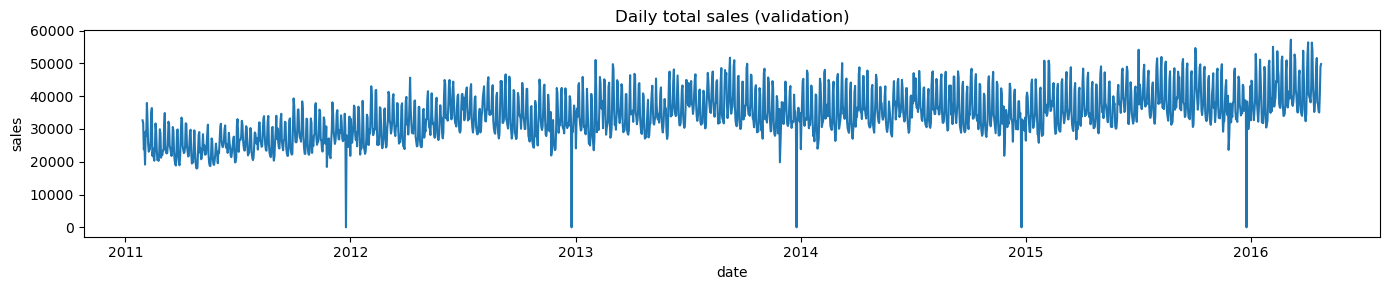

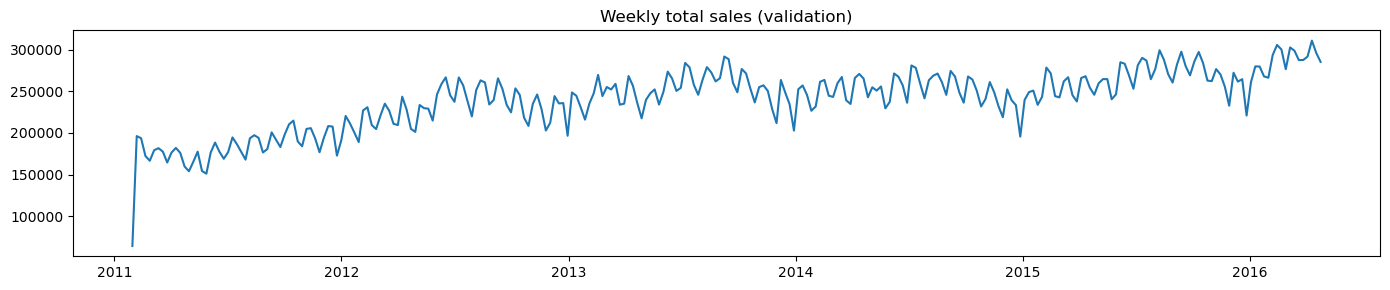

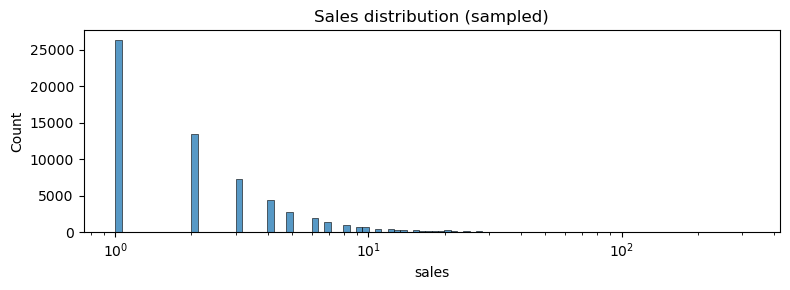

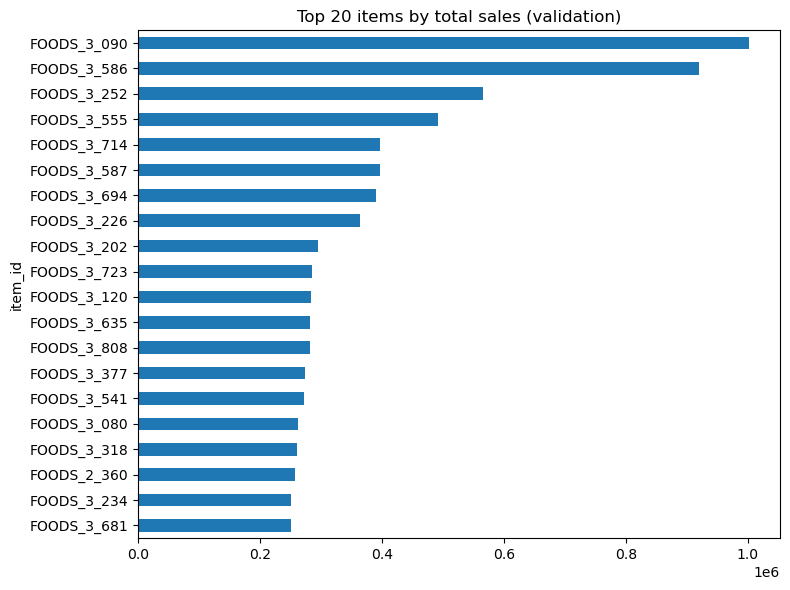

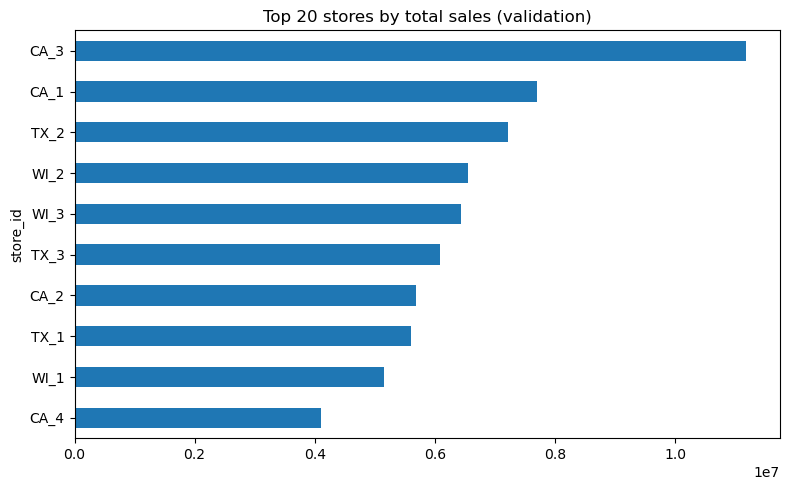

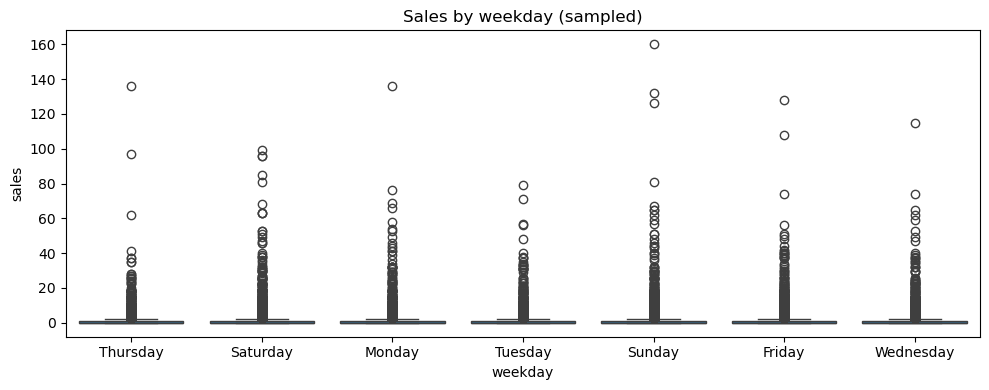

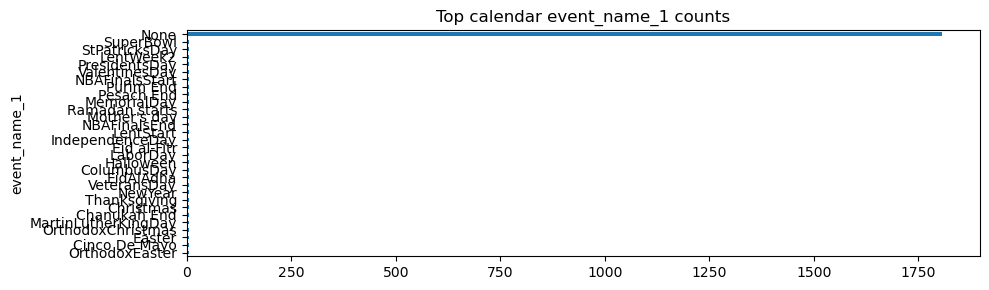


Sell_prices sample & summary:


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


count    6.841121e+06
mean     4.410952e+00
std      3.408814e+00
min      1.000000e-02
25%      2.180000e+00
50%      3.470000e+00
75%      5.840000e+00
max      1.073200e+02
Name: sell_price, dtype: float64


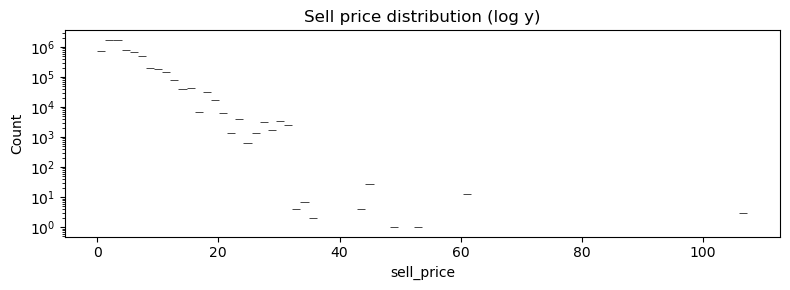


Missing fraction in prices frame:
 store_id      0.0
item_id       0.0
wm_yr_wk      0.0
sell_price    0.0
dtype: float64

Sales with prices merged shape: (58327370, 14)
Fraction rows with price: 0.7891313632005009


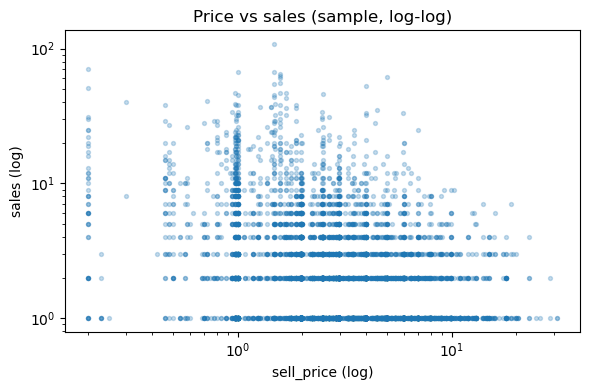

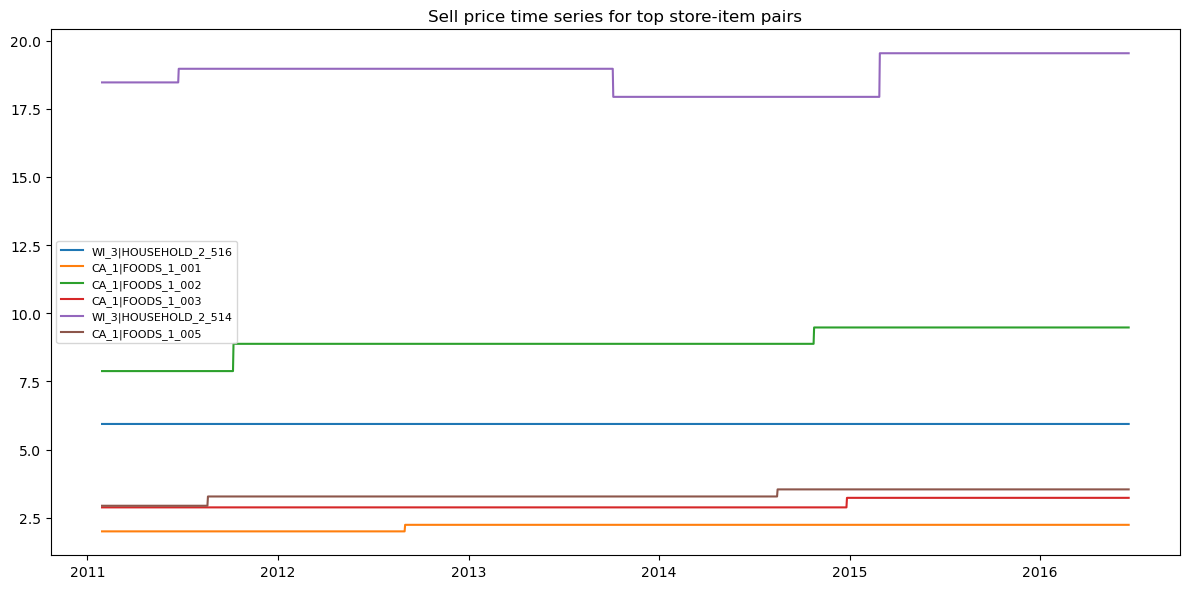


Evaluation set shape: (30490, 1947)


,id,item_id,dept_id,cat_id,store_id,state_id,d_1914,d_1915,d_1916,d_1917,d_1918,d_1919,d_1920,d_1921,d_1922,d_1923,d_1924,d_1925,d_1926,d_1927,d_1928,d_1929,d_1930,d_1931,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,2,0,3,5,0,0,1,1,0,2,1,2,2,1,0,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,1,1,0,2,1,0,0,0,0,2,1,3,0,0,1,0,1,0,2,0,0,0,2,3,0,1


In [3]:
# EDA for M5 retail dataset files
# Assumes pandas, numpy, matplotlib.pyplot as plt and seaborn as sns are available from previous cells

# load files
cal = pd.read_csv("datasets/m5-retail-dataset/calendar.csv", parse_dates=["date"])
prices = pd.read_csv("datasets/m5-retail-dataset/sell_prices.csv")
sales_val = pd.read_csv("datasets/m5-retail-dataset/sales_train_validation.csv")
sales_eval = pd.read_csv("datasets/m5-retail-dataset/sales_train_evaluation.csv")

print("calendar:", cal.shape)
print("sell_prices:", prices.shape)
print("sales_train_validation:", sales_val.shape)
print("sales_train_evaluation:", sales_eval.shape)

# melt sales to long format (validation set)
meta_cols = [c for c in sales_val.columns if not c.startswith("d_")]
sales_val_long = sales_val.melt(id_vars=meta_cols, var_name="d", value_name="sales")
sales_val_long = sales_val_long.merge(cal[["d", "date", "wm_yr_wk", "weekday", "event_name_1", "event_type_1"]], on="d", how="left")
sales_val_long["sales"] = sales_val_long["sales"].astype(float)

# quick summaries
print("\nValidation long shape:", sales_val_long.shape)
print("Unique items:", sales_val_long["item_id"].nunique())
print("Unique stores:", sales_val_long["store_id"].nunique())

# daily total sales (validation)
daily = sales_val_long.groupby("date")["sales"].sum().reset_index()
plt.figure(figsize=(14,3))
plt.plot(daily["date"], daily["sales"])
plt.title("Daily total sales (validation)")
plt.xlabel("date")
plt.ylabel("sales")
plt.tight_layout()
plt.show()

# weekly aggregated time series
weekly = sales_val_long.groupby(pd.Grouper(key="date", freq="W"))["sales"].sum().reset_index()
plt.figure(figsize=(14,3))
plt.plot(weekly["date"], weekly["sales"])
plt.title("Weekly total sales (validation)")
plt.tight_layout()
plt.show()

# distribution of sales (sampled)
plt.figure(figsize=(8,3))
sns.histplot(sales_val_long["sales"].sample(min(200000, len(sales_val_long)), random_state=0), bins=100, log_scale=(True, False))
plt.title("Sales distribution (sampled)")
plt.tight_layout()
plt.show()

# top 20 items by total sales
top_items = sales_val_long.groupby("item_id")["sales"].sum().sort_values(ascending=False).head(20)
plt.figure(figsize=(8,6))
top_items.sort_values().plot(kind="barh")
plt.title("Top 20 items by total sales (validation)")
plt.tight_layout()
plt.show()

# top stores by total sales
top_stores = sales_val_long.groupby("store_id")["sales"].sum().sort_values(ascending=False).head(20)
plt.figure(figsize=(8,5))
top_stores.sort_values().plot(kind="barh")
plt.title("Top 20 stores by total sales (validation)")
plt.tight_layout()
plt.show()

# weekday patterns (boxplot on sample)
sample_wd = sales_val_long.sample(min(50000, len(sales_val_long)), random_state=1)
plt.figure(figsize=(10,4))
sns.boxplot(x="weekday", y="sales", data=sample_wd)
plt.title("Sales by weekday (sampled)")
plt.tight_layout()
plt.show()

# event counts on calendar
evt1 = cal["event_name_1"].fillna("None")
plt.figure(figsize=(10,3))
evt1.value_counts().head(30).sort_values().plot(kind="barh")
plt.title("Top calendar event_name_1 counts")
plt.tight_layout()
plt.show()

# sell_prices overview
print("\nSell_prices sample & summary:")
display(prices.head())
print(prices["sell_price"].describe())

plt.figure(figsize=(8,3))
sns.histplot(prices["sell_price"].dropna(), bins=80, log_scale=(False, True))
plt.title("Sell price distribution (log y)")
plt.tight_layout()
plt.show()

# fraction of missing prices by store/item
missing_prices = prices.isna().mean()
print("\nMissing fraction in prices frame:\n", missing_prices)

# join sales + price via wm_yr_wk, store_id, item_id (sample for performance)
sales_with_wk = sales_val_long.merge(prices, on=["store_id", "item_id", "wm_yr_wk"], how="left")
print("\nSales with prices merged shape:", sales_with_wk.shape)
print("Fraction rows with price:", sales_with_wk["sell_price"].notna().mean())

# scatter price vs sales (sample)
scatter_sample = sales_with_wk.dropna(subset=["sell_price"]).sample(min(15000, sales_with_wk["sell_price"].dropna().shape[0]), random_state=2)
plt.figure(figsize=(6,4))
plt.scatter(scatter_sample["sell_price"], scatter_sample["sales"], alpha=0.25, s=8)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("sell_price (log)")
plt.ylabel("sales (log)")
plt.title("Price vs sales (sample, log-log)")
plt.tight_layout()
plt.show()

# examine price time series for a few item-store combos
pairs = prices.groupby(["store_id","item_id"])["sell_price"].count().sort_values(ascending=False).head(6).index.tolist()
plt.figure(figsize=(12,6))
for store_id, item_id in pairs:
    tmp = prices[(prices["store_id"]==store_id)&(prices["item_id"]==item_id)].merge(cal[["wm_yr_wk","date"]], on="wm_yr_wk", how="left").sort_values("date")
    plt.plot(tmp["date"], tmp["sell_price"], label=f"{store_id}|{item_id}")
plt.legend(fontsize=8)
plt.title("Sell price time series for top store-item pairs")
plt.tight_layout()
plt.show()

# Quick look at evaluation set shape and a small melt for comparison (no full melt to save memory)
print("\nEvaluation set shape:", sales_eval.shape)
meta_eval = [c for c in sales_eval.columns if not c.startswith("d_")]
eval_sample = sales_eval[meta_eval + sales_eval.columns[-28:].tolist()].head(3)  # show last 28 forecast columns sample
display(eval_sample)

# End of cell


HOLIDAYS
Shape: (350, 6)

Dtypes:
date           object
type           object
locale         object
locale_name    object
description    object
transferred      bool
dtype: object

Missing Values:
date           0
type           0
locale         0
locale_name    0
description    0
transferred    0
dtype: int64

Head:
         date     type    locale locale_name                    description  \
0  2012-03-02  Holiday     Local       Manta             Fundacion de Manta   
1  2012-04-01  Holiday  Regional    Cotopaxi  Provincializacion de Cotopaxi   
2  2012-04-12  Holiday     Local      Cuenca            Fundacion de Cuenca   
3  2012-04-14  Holiday     Local    Libertad      Cantonizacion de Libertad   
4  2012-04-21  Holiday     Local    Riobamba      Cantonizacion de Riobamba   

   transferred  
0        False  
1        False  
2        False  
3        False  
4        False  

ITEMS
Shape: (4100, 4)

Dtypes:
item_nbr       int64
family        object
class          int64
perisha

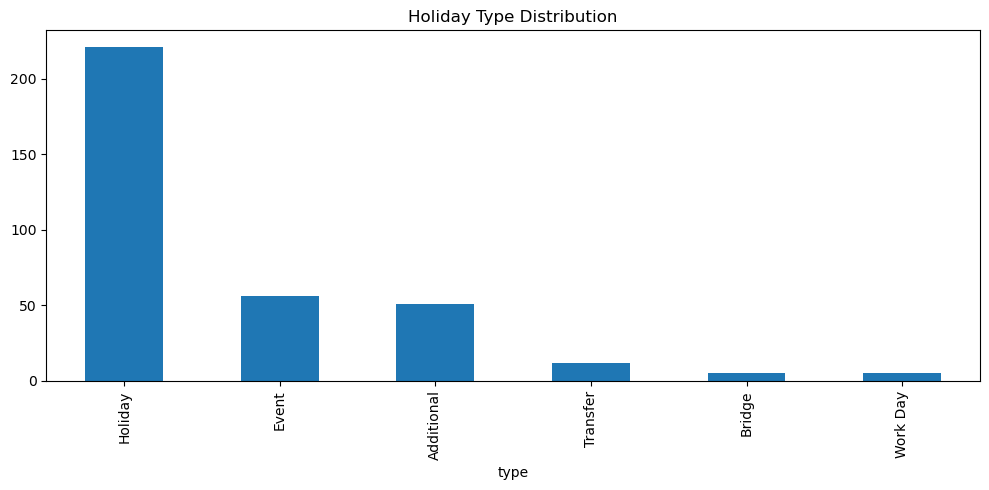

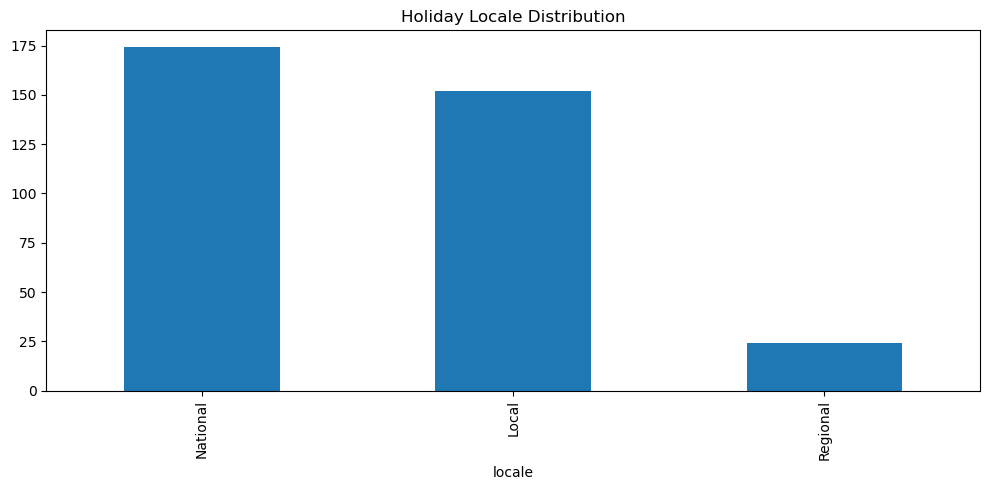

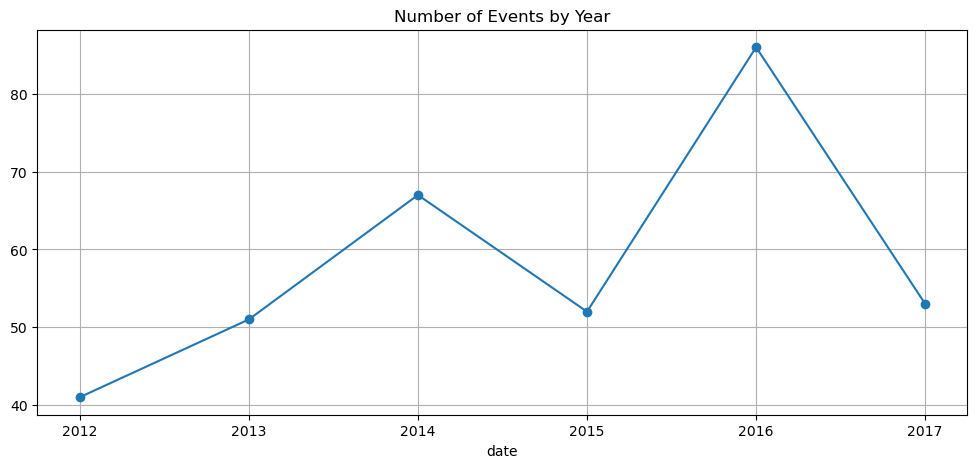


ITEMS SUMMARY
--------------------------------------------------------------------------------
Unique Families: 33

Top Families
family
GROCERY I              1334
BEVERAGES               613
CLEANING                446
PRODUCE                 306
DAIRY                   242
PERSONAL CARE           153
BREAD/BAKERY            134
HOME CARE               108
DELI                     91
MEATS                    84
HOME AND KITCHEN I       77
LIQUOR,WINE,BEER         73
FROZEN FOODS             55
POULTRY                  54
HOME AND KITCHEN II      45
EGGS                     41
CELEBRATION              31
LAWN AND GARDEN          26
PREPARED FOODS           26
LADIESWEAR               21
Name: count, dtype: int64


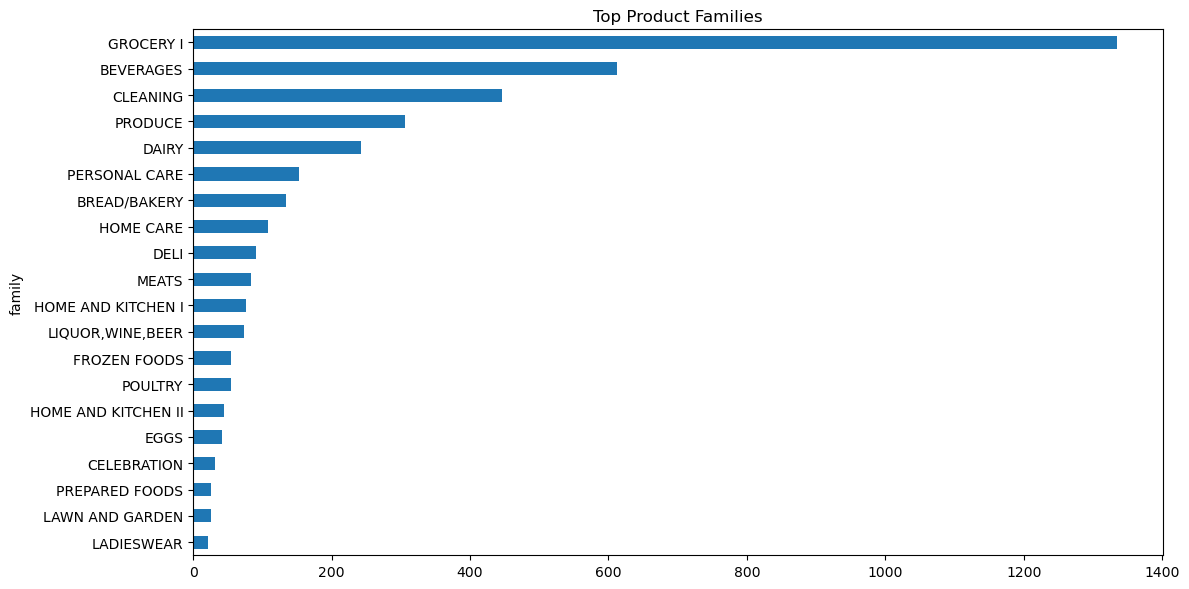

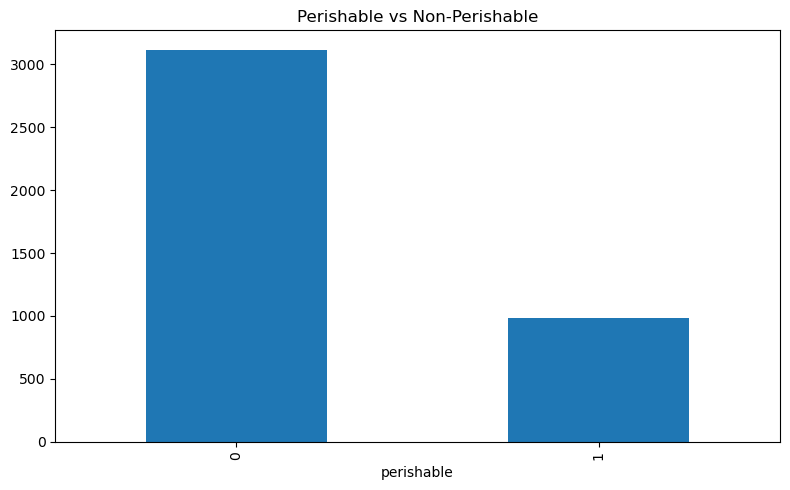

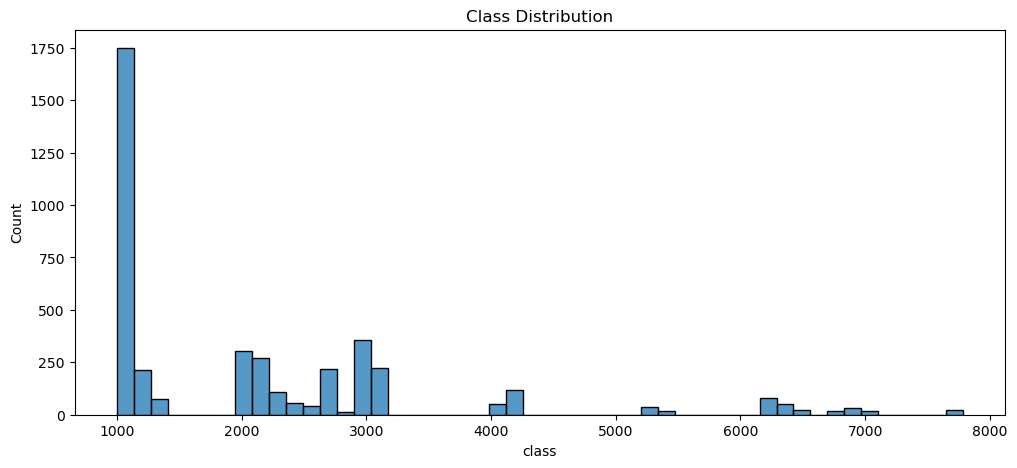


OIL SUMMARY
--------------------------------------------------------------------------------
count    1175.000000
mean       67.714366
std        25.630476
min        26.190000
25%        46.405000
50%        53.190000
75%        95.660000
max       110.620000
Name: dcoilwtico, dtype: float64
Missing Oil Values: 43


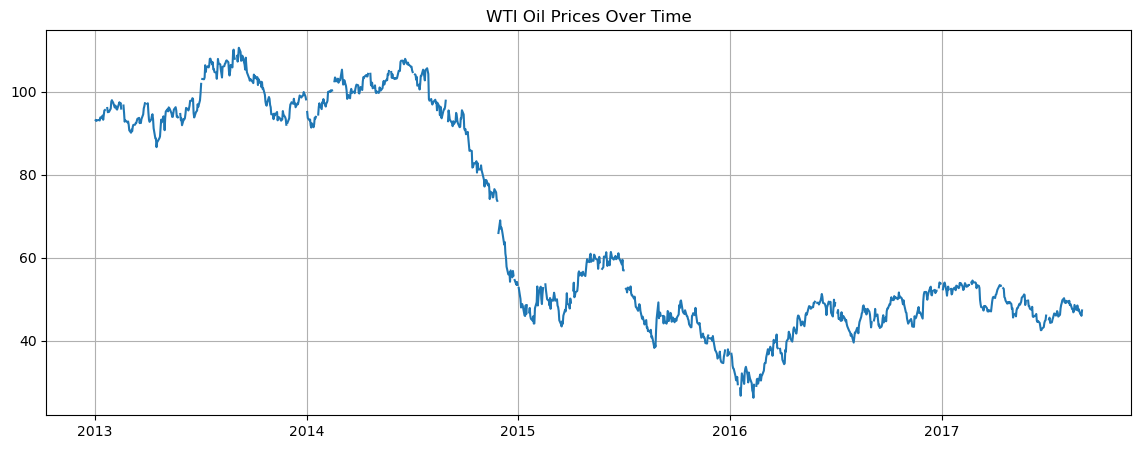

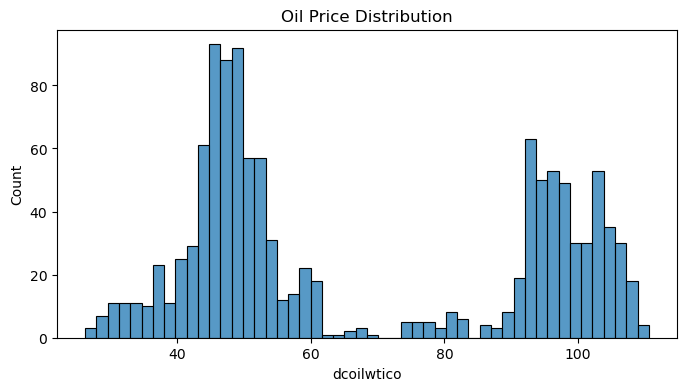


STORES SUMMARY
--------------------------------------------------------------------------------
Stores: 54

Cities:
22

States:
16

Store Types:
type
D    18
C    15
A     9
B     8
E     4
Name: count, dtype: int64

Clusters:
cluster
1     3
2     2
3     7
4     3
5     1
6     6
7     2
8     3
9     2
10    6
11    3
12    1
13    4
14    4
15    5
16    1
17    1
Name: count, dtype: int64


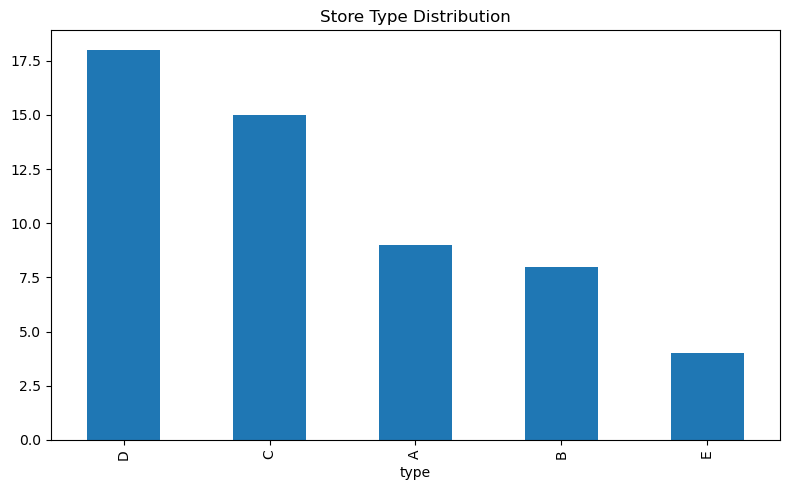

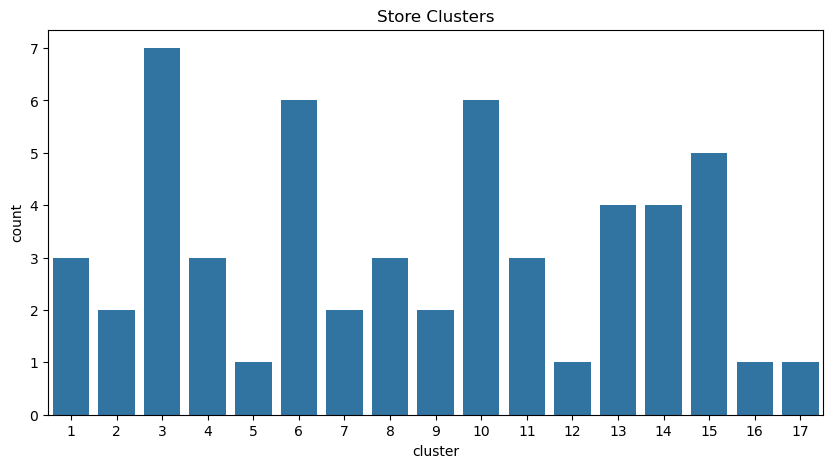

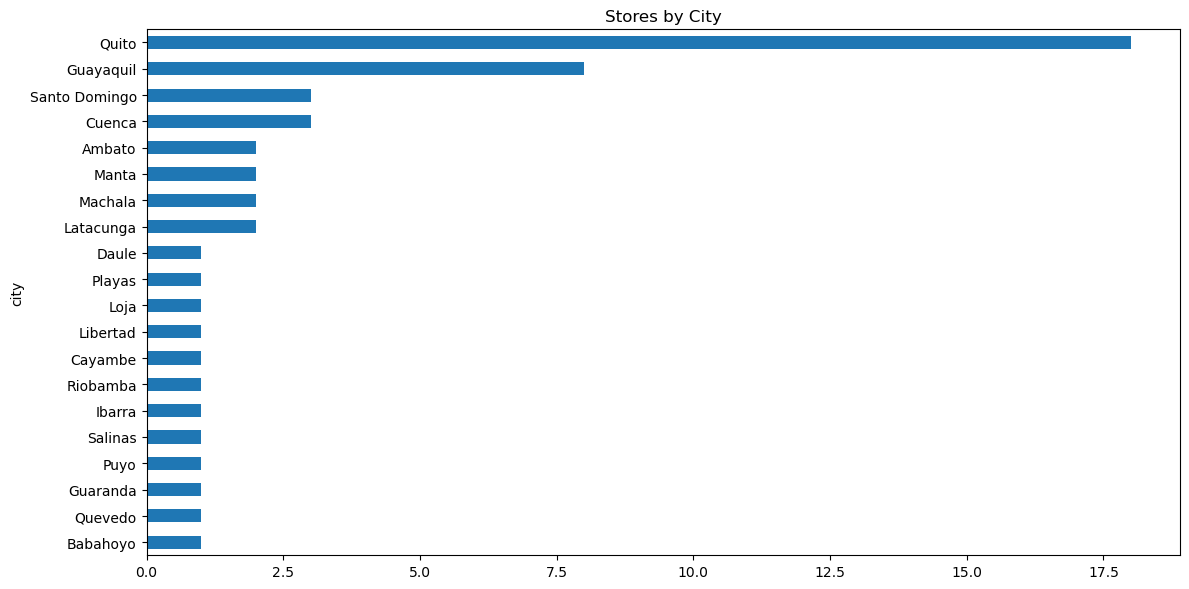


TRANSACTIONS SUMMARY
--------------------------------------------------------------------------------
count    83488.000000
mean      1694.602158
std        963.286644
min          5.000000
25%       1046.000000
50%       1393.000000
75%       2079.000000
max       8359.000000
Name: transactions, dtype: float64


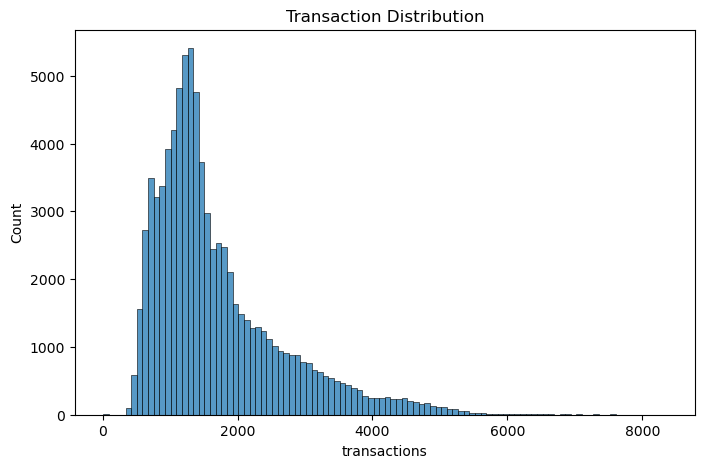

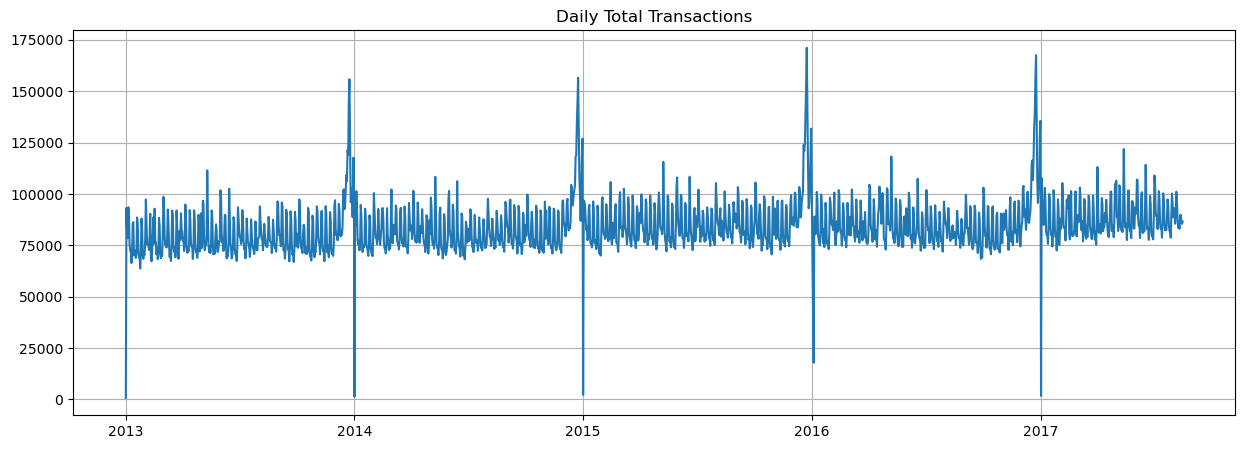

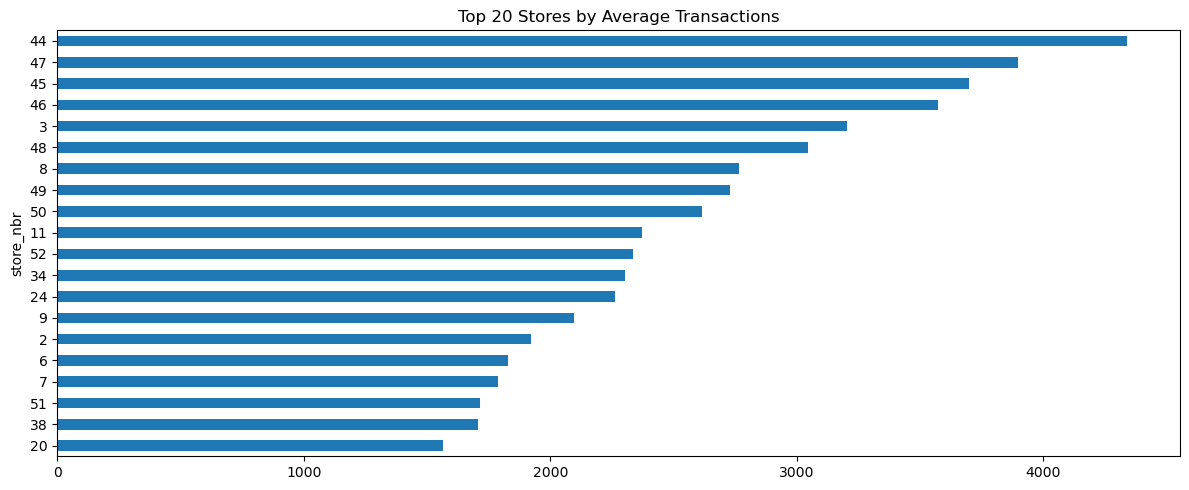


RELATIONSHIP CHECKS
--------------------------------------------------------------------------------

Transaction Date Range: 2013-01-01 00:00:00 to 2017-08-15 00:00:00

Oil Date Range: 2013-01-01 00:00:00 to 2017-08-31 00:00:00

Holiday Date Range: 2012-03-02 00:00:00 to 2017-12-26 00:00:00


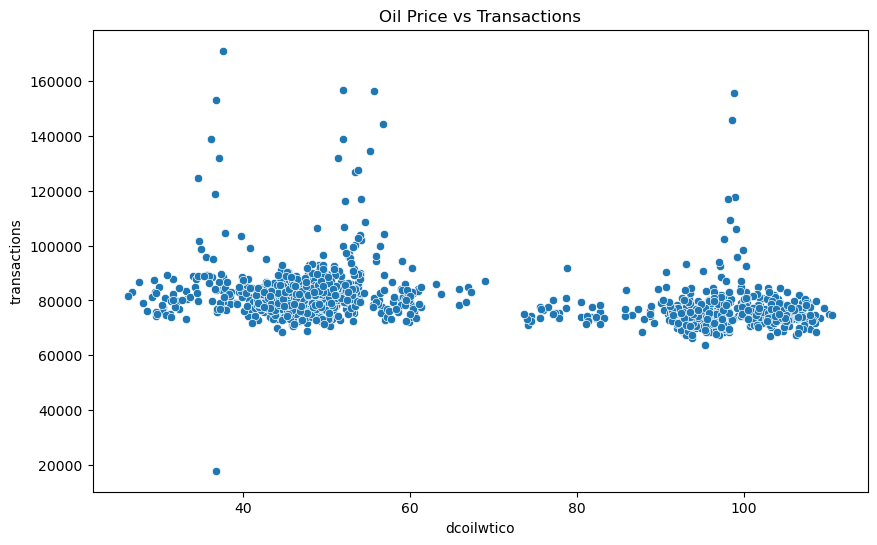


EDA COMPLETE


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("default")
pd.set_option("display.max_columns", None)

# =====================================================
# LOAD FILES
# =====================================================

holidays = pd.read_csv("datasets/favorita-retail-dataset/holidays_events.csv")
items = pd.read_csv("datasets/favorita-retail-dataset/items.csv")
oil = pd.read_csv("datasets/favorita-retail-dataset/oil.csv")
stores = pd.read_csv("datasets/favorita-retail-dataset/stores.csv")
transactions = pd.read_csv("datasets/favorita-retail-dataset/transactions.csv")

# =====================================================
# BASIC OVERVIEW
# =====================================================

datasets = {
    "HOLIDAYS": holidays,
    "ITEMS": items,
    "OIL": oil,
    "STORES": stores,
    "TRANSACTIONS": transactions
}

for name, df in datasets.items():

    print("\n" + "="*100)
    print(name)
    print("="*100)

    print("Shape:", df.shape)

    print("\nDtypes:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isna().sum())

    print("\nHead:")
    print(df.head())

# =====================================================
# HOLIDAYS EDA
# =====================================================

print("\nHOLIDAYS SUMMARY")
print("-"*80)

holidays["date"] = pd.to_datetime(holidays["date"])

print("Holiday Types")
print(holidays["type"].value_counts())

print("\nLocales")
print(holidays["locale"].value_counts())

print("\nTransferred")
print(holidays["transferred"].value_counts())

plt.figure(figsize=(10,5))
holidays["type"].value_counts().plot(kind="bar")
plt.title("Holiday Type Distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,5))
holidays["locale"].value_counts().plot(kind="bar")
plt.title("Holiday Locale Distribution")
plt.tight_layout()
plt.show()

holiday_yearly = holidays.groupby(holidays["date"].dt.year).size()

plt.figure(figsize=(12,5))
holiday_yearly.plot(marker="o")
plt.title("Number of Events by Year")
plt.grid()
plt.show()

# =====================================================
# ITEMS EDA
# =====================================================

print("\nITEMS SUMMARY")
print("-"*80)

print("Unique Families:", items["family"].nunique())

print("\nTop Families")
print(items["family"].value_counts().head(20))

plt.figure(figsize=(12,6))
items["family"].value_counts().head(20).sort_values().plot(kind="barh")
plt.title("Top Product Families")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))
items["perishable"].value_counts().plot(kind="bar")
plt.title("Perishable vs Non-Perishable")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,5))
sns.histplot(items["class"], bins=50)
plt.title("Class Distribution")
plt.show()

# =====================================================
# OIL EDA
# =====================================================

print("\nOIL SUMMARY")
print("-"*80)

oil["date"] = pd.to_datetime(oil["date"])
oil["dcoilwtico"] = pd.to_numeric(oil["dcoilwtico"], errors="coerce")

print(oil["dcoilwtico"].describe())

print("Missing Oil Values:",
      oil["dcoilwtico"].isna().sum())

plt.figure(figsize=(14,5))
plt.plot(oil["date"], oil["dcoilwtico"])
plt.title("WTI Oil Prices Over Time")
plt.grid()
plt.show()

plt.figure(figsize=(8,4))
sns.histplot(oil["dcoilwtico"].dropna(), bins=50)
plt.title("Oil Price Distribution")
plt.show()

# =====================================================
# STORES EDA
# =====================================================

print("\nSTORES SUMMARY")
print("-"*80)

print("Stores:", stores["store_nbr"].nunique())

print("\nCities:")
print(stores["city"].nunique())

print("\nStates:")
print(stores["state"].nunique())

print("\nStore Types:")
print(stores["type"].value_counts())

print("\nClusters:")
print(stores["cluster"].value_counts().sort_index())

plt.figure(figsize=(8,5))
stores["type"].value_counts().plot(kind="bar")
plt.title("Store Type Distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,5))
sns.countplot(data=stores, x="cluster")
plt.title("Store Clusters")
plt.show()

plt.figure(figsize=(12,6))
stores["city"].value_counts().head(20).sort_values().plot(kind="barh")
plt.title("Stores by City")
plt.tight_layout()
plt.show()

# =====================================================
# TRANSACTIONS EDA
# =====================================================

print("\nTRANSACTIONS SUMMARY")
print("-"*80)

transactions["date"] = pd.to_datetime(transactions["date"])

print(transactions["transactions"].describe())

plt.figure(figsize=(8,5))
sns.histplot(
    transactions["transactions"],
    bins=100
)
plt.title("Transaction Distribution")
plt.show()

daily_transactions = (
    transactions
    .groupby("date")["transactions"]
    .sum()
)

plt.figure(figsize=(15,5))
plt.plot(daily_transactions.index,
         daily_transactions.values)
plt.title("Daily Total Transactions")
plt.grid()
plt.show()

store_transactions = (
    transactions
    .groupby("store_nbr")["transactions"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12,5))
store_transactions.head(20).sort_values().plot(kind="barh")
plt.title("Top 20 Stores by Average Transactions")
plt.tight_layout()
plt.show()

# =====================================================
# RELATIONSHIP ANALYSIS
# =====================================================

print("\nRELATIONSHIP CHECKS")
print("-"*80)

print(
    "\nTransaction Date Range:",
    transactions["date"].min(),
    "to",
    transactions["date"].max()
)

print(
    "\nOil Date Range:",
    oil["date"].min(),
    "to",
    oil["date"].max()
)

print(
    "\nHoliday Date Range:",
    holidays["date"].min(),
    "to",
    holidays["date"].max()
)

# Oil + Transactions

oil_daily = oil.set_index("date")["dcoilwtico"]

combined = (
    daily_transactions
    .to_frame("transactions")
    .join(oil_daily)
)

plt.figure(figsize=(10,6))
sns.scatterplot(
    data=combined,
    x="dcoilwtico",
    y="transactions"
)

plt.title("Oil Price vs Transactions")
plt.show()

print("\nEDA COMPLETE")

c:\Users\SafinSharma\miniconda3\envs\work\Lib\site-packages\pandas\core\indexes\base.py:7654: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)


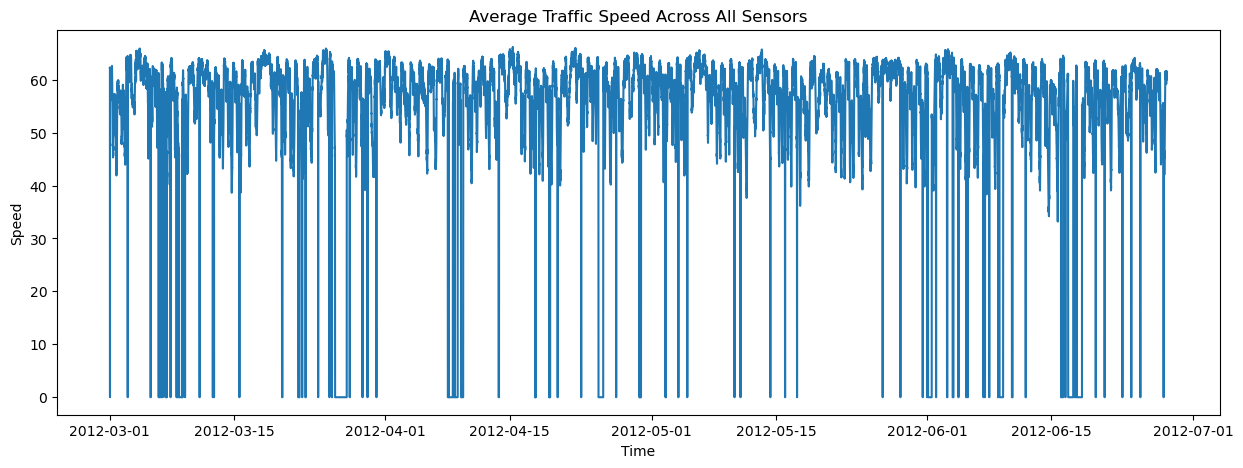

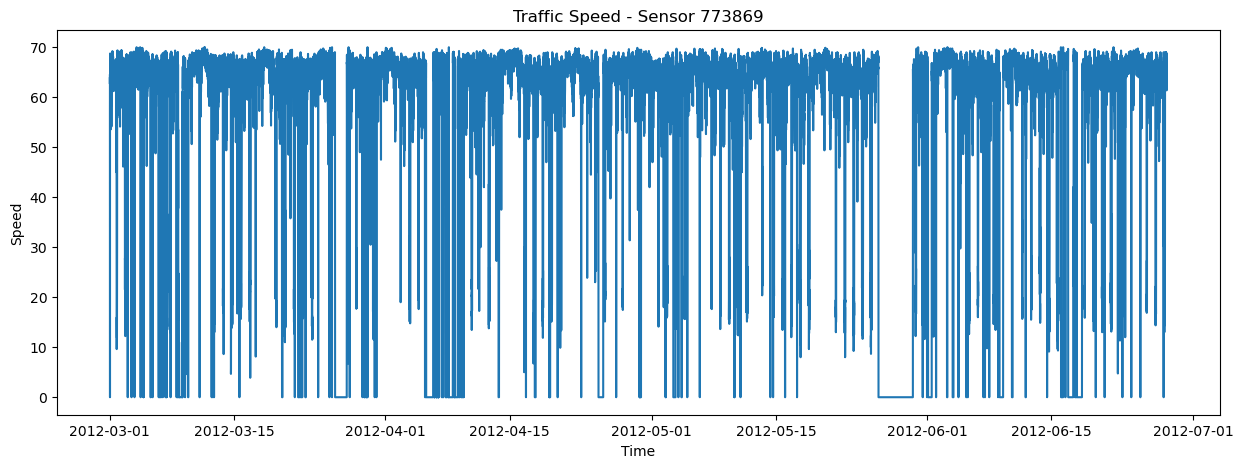

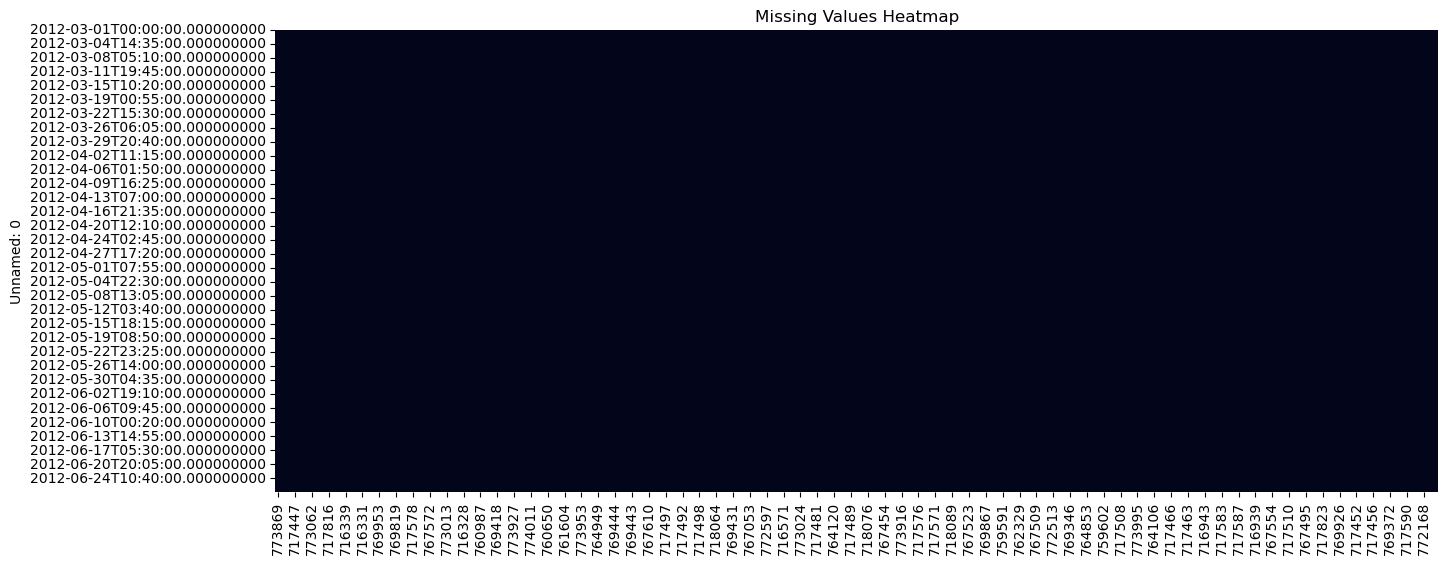

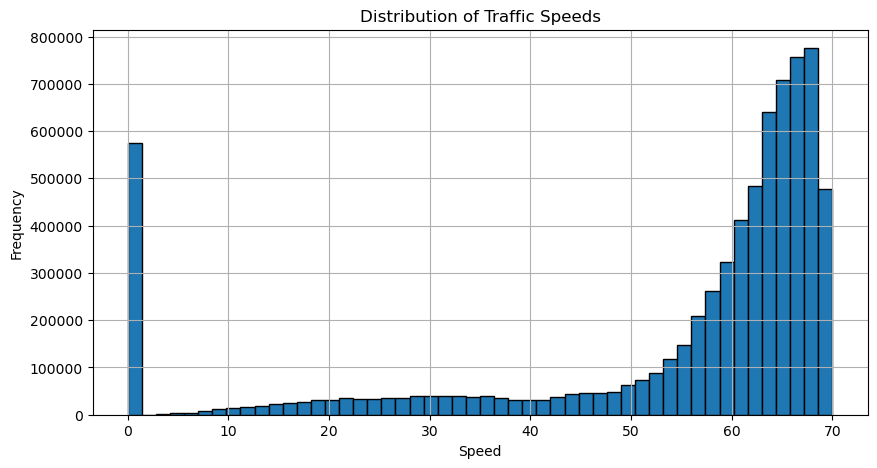

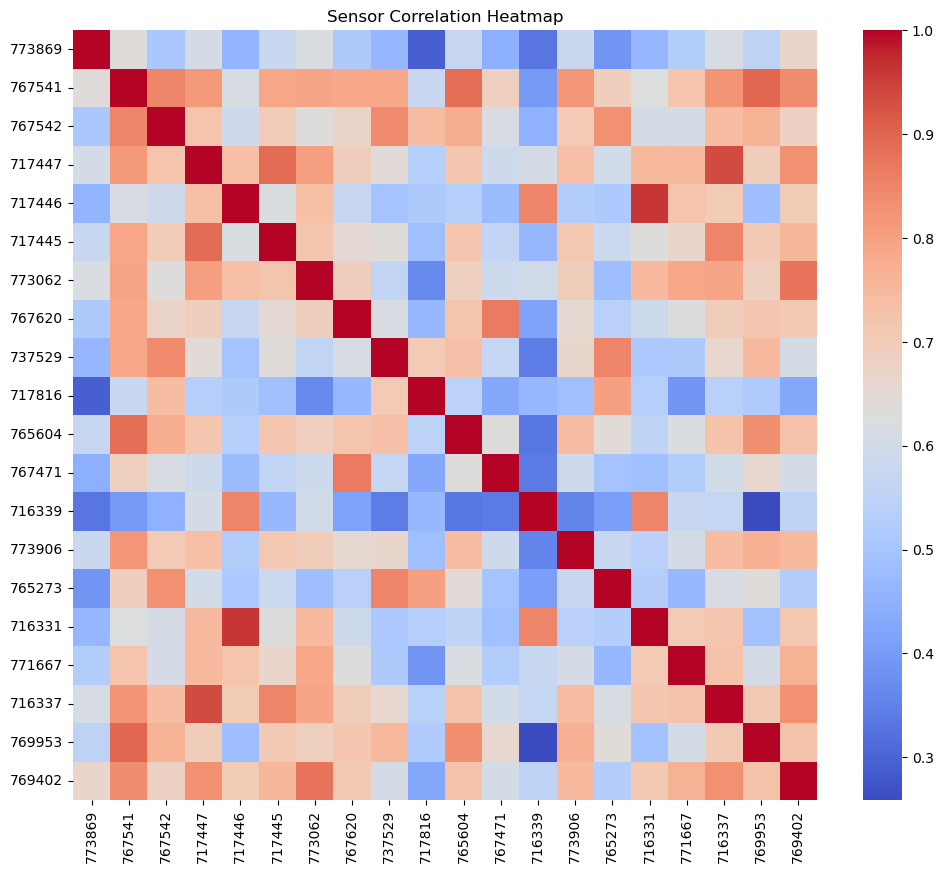

C:\Users\SafinSharma\AppData\Local\Temp\ipykernel_16688\3438117997.py:57: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  hourly = df.resample("H").mean()


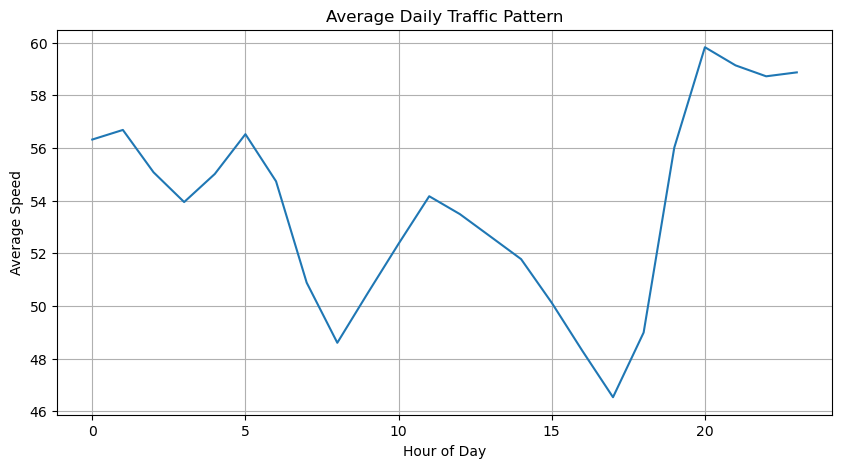

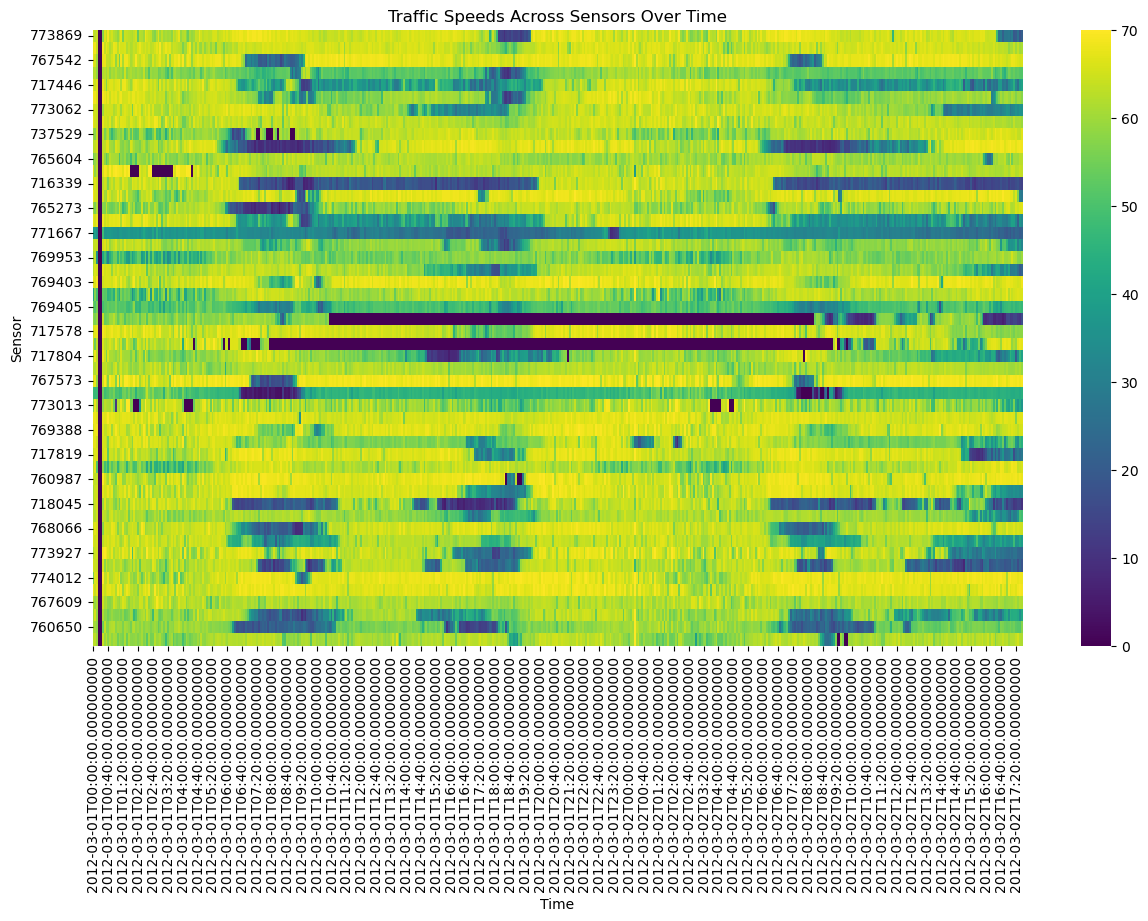

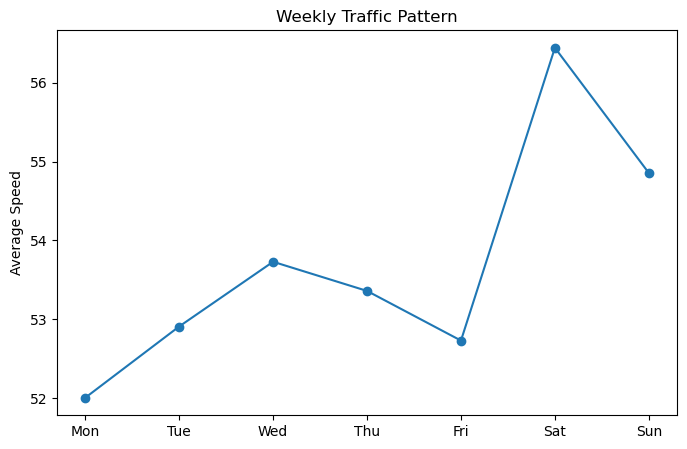

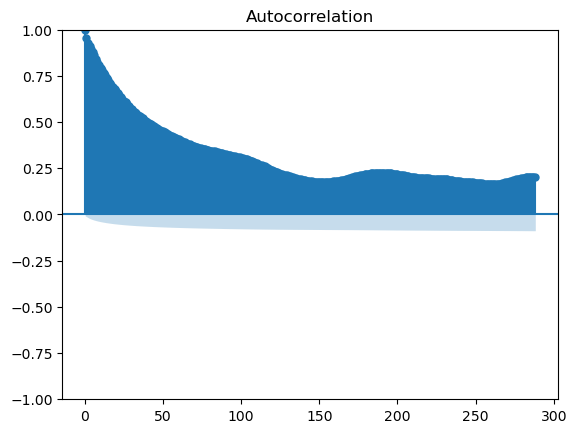

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("datasets/METR-LA.csv")

df.iloc[:, 0] = pd.to_datetime(df.iloc[:, 0])
df = df.set_index(df.columns[0])

avg_speed = df.mean(axis=1)

plt.figure(figsize=(15,5))
plt.plot(avg_speed)
plt.title("Average Traffic Speed Across All Sensors")
plt.xlabel("Time")
plt.ylabel("Speed")
plt.show()

sensor = "773869"

plt.figure(figsize=(15,5))
plt.plot(df[sensor])
plt.title(f"Traffic Speed - Sensor {sensor}")
plt.xlabel("Time")
plt.ylabel("Speed")
plt.show()

import seaborn as sns

plt.figure(figsize=(15,6))
sns.heatmap(df.isna(), cbar=False)
plt.title("Missing Values Heatmap")
plt.show()

plt.figure(figsize=(10,5))

all_values = df.values.flatten()

pd.Series(all_values).hist(
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Traffic Speeds")
plt.xlabel("Speed")
plt.ylabel("Frequency")
plt.show()

sample = df.iloc[:, :20]

corr = sample.corr()

plt.figure(figsize=(12,10))
sns.heatmap(corr, cmap="coolwarm")
plt.title("Sensor Correlation Heatmap")
plt.show()

hourly = df.resample("H").mean()

daily_pattern = hourly.groupby(hourly.index.hour).mean().mean(axis=1)

plt.figure(figsize=(10,5))
plt.plot(daily_pattern)

plt.title("Average Daily Traffic Pattern")
plt.xlabel("Hour of Day")
plt.ylabel("Average Speed")
plt.grid(True)
plt.show()


sample = df.iloc[:500, :50]

plt.figure(figsize=(15,8))
sns.heatmap(sample.T, cmap="viridis")

plt.title("Traffic Speeds Across Sensors Over Time")
plt.xlabel("Time")
plt.ylabel("Sensor")
plt.show()

daily_avg = df.mean(axis=1)

weekly = (
    daily_avg
    .groupby(daily_avg.index.dayofweek)
    .mean()
)

days = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]

plt.figure(figsize=(8,5))
plt.plot(days, weekly, marker="o")
plt.title("Weekly Traffic Pattern")
plt.ylabel("Average Speed")
plt.show()

from statsmodels.graphics.tsaplots import plot_acf

avg_speed = df.mean(axis=1)

plot_acf(avg_speed, lags=288)
plt.show()

